# Instrukcja - Transformacja Hougha

### Cel:
- zapoznanie z transformacją Hougha dla pojedynczego punktu,
- kilku punktów, prostych figur
- wykorzystanie transformacji Hougha do detekcji linii prostych na rzeczywistym obrazie
- transformacja Hougha w przestrzeni ab

### Transformacja Hough'a

Transformacja Hougha dla prostych jest metodą detekcji współliniowych punktów. Każda prosta może być jednoznacznie przedstawiona za pomocą dwóch parametrów. Przestrzeń tych parametrów to przestrzeń Hougha. Najczęściej wykorzystywanymi parametrami w tej metodzie są współczynniki ρ,θ

opisujące równanie prostej w postaci normalnej:

ρ=x⋅cos(θ)+y⋅sin(θ)

gdzie: ρ - promień wodzący, θ - kąt pomiędzy ρ a osią OX.

Własności transformacji Hougha:
- prostej w przestrzeni kartezjańskiej odpowiada punkt w przestrzeni Hougha
- pękowi prostych przechdzących przez punkt w przestrzeni kartezjańskiej odpowiada krzywa sinusoidalna w przestrzeni Hougha
- punkty leżące na tej samej prostej (w przestrzeni kartezjańskiej) korespondują z sinusoidami przechodzącymi przez wspólny punkt w przestrzeni Hougha.

Metoda wyliczania transformacji Hougha składa się z następujących kroków:
- przez każdy badany (różny od zera) punkt obrazu prowadzony jest pęk prostych, przechodzących przez ten punkt
- każda z tych prostych transformowana jest do przestrzeni Hougha i tworzy tam punkt o współrzędnych ρ,θ
- w ten sposób, każdy punkt obrazu pierwotnego (pęk prostych) jest odwzorowany w sinusoidalną krzywą w przestrzeni Hougha

Przestrzeń Hougha jest przestrzenią akumulacyjną tzn. punkty sinusoidalnych krzywych, wygenerowanych dla punktów obrazu pierwotnego dodają się w miejscach, w których krzywe te przecinają się. Powstałe w ten sposób (w przestrzeni Hougha) maksima odpowiadają zbiorom punktów, należących do jednej prostej. Współrzędne ρ,θ
tego maksimum jednoznacznie określają położenie prostej na obrazie pierwotnym.

### Transformacja Hougha dla małej liczby punktów.
   1. Uruchom poniższy kod. W tablicy `im` wskaż jeden punkt, dla którego ma zostać obliczona transformata.

(np.float64(-0.5), np.float64(63.5), np.float64(63.5), np.float64(-0.5))

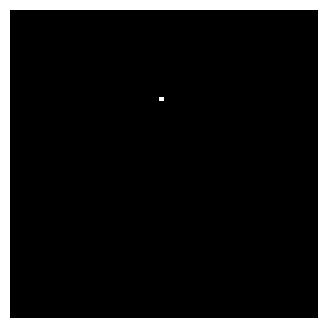

In [30]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from skimage.transform import hough_line, hough_line_peaks
import os
import requests

url = 'https://raw.githubusercontent.com/vision-agh/poc_sw/master/11_Hough/'

fileNames = ["dom.png", "kwadraty.png", "lab112.png"]
for fileName in fileNames:
  if not os.path.exists(fileName):
      r = requests.get(url + fileName, allow_redirects=True)
      open(fileName, 'wb').write(r.content)

im = np.zeros((64,64), dtype=np.uint8)

im[18, 31] = 1

fig, ax = plt.subplots()
fig.set_size_inches(4, 4)
ax.imshow(im, 'gray')
ax.axis('off')

3. Wykonaj transformację Hougha obazu im. Wykorzystaj funkcję *hough_line* z modułu _skimage.transform_. Funkcja zwraca: macierz H (przestrzeń Hougha) oraz dwa wektory theta i rho dla kolejnych 
4. Wyświetl przestrzeń Hougha za pomocą funkcji _plt.imshow_ (można też wykorzystać poniższą funkcję *show_hough*). Jak "wygląda" pojedynczy punkt w przestrzeni Hougha?

In [31]:
def show_hough(h, image):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    ax = axes.ravel()

    ax[0].imshow(image, 'gray')
    ax[0].set_title('Input image')
    ax[0].set_axis_off()

    ax[1].imshow(h, 'gray')
    ax[1].set_title('Hough transform')
    ax[1].set_xlabel('Angles (degrees)')
    ax[1].set_ylabel('Distance (pixels)')
    ax[1].axis('image')
    
    plt.tight_layout()
    plt.show()    

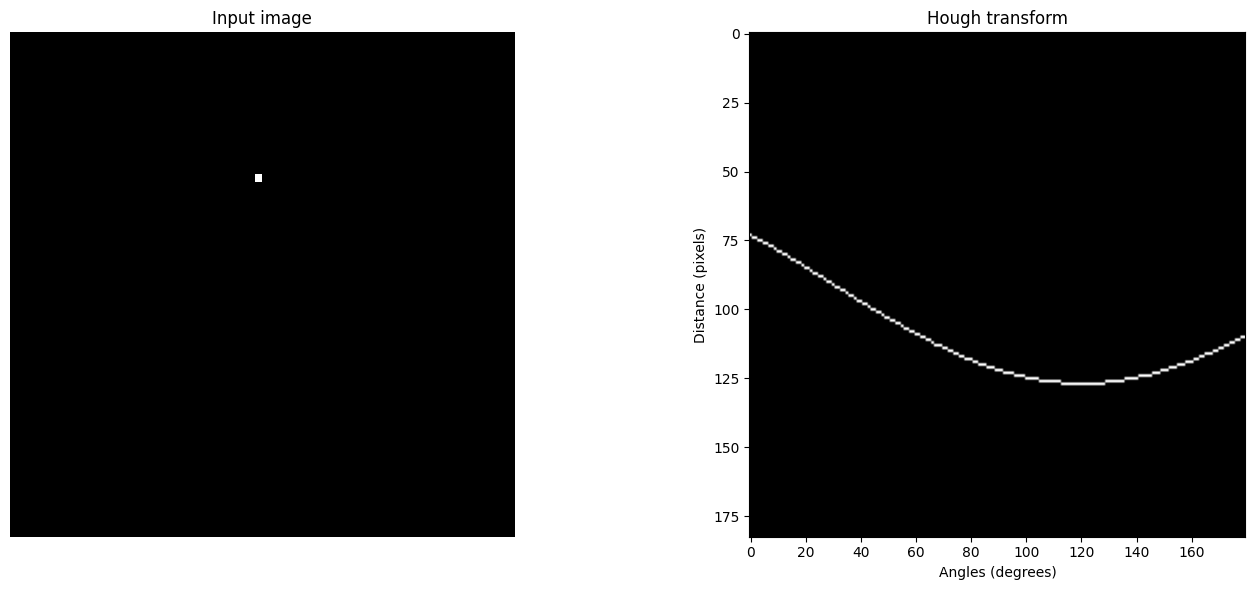

In [32]:
h, theta, rho = hough_line(im)
show_hough(h, im)

5. Powtórz punkty 1-4, ale tym razem klinkij dwa punkty. Jak zmienia się przestrzeń Hougha?
6. Powtórz punkty 1-4, ale tym razem kliknij kilka punktów starając się aby były współliniowe. Zaobserwuj zmiany w przestrzeni Hougha
7. Poeksperymentuj z różnymi układami punktów

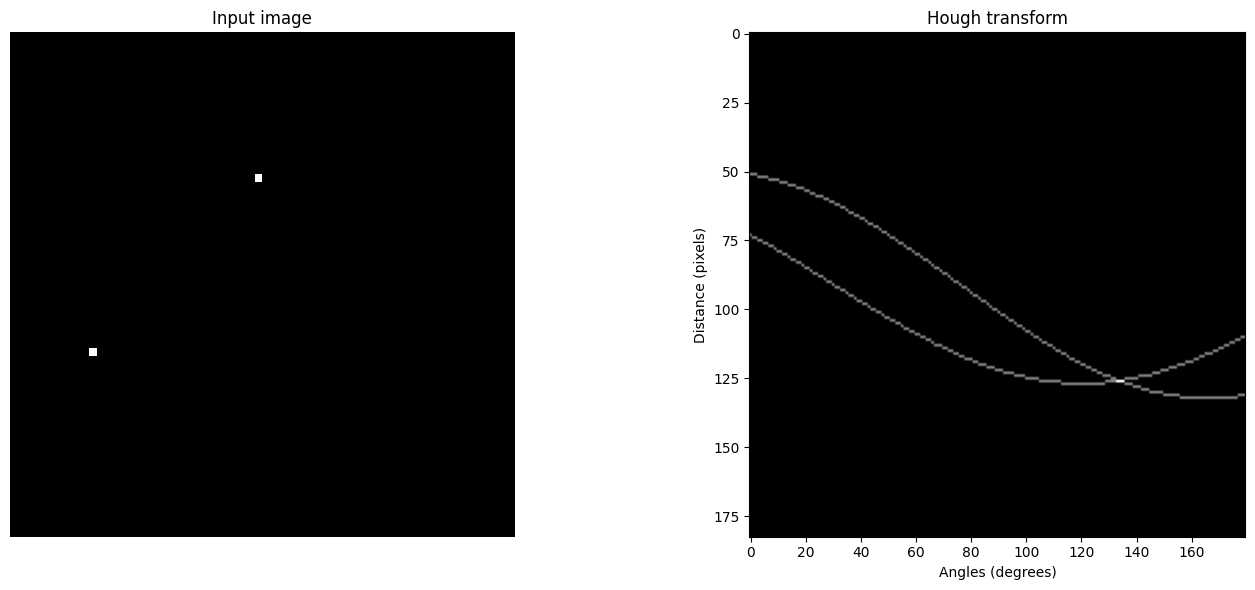

In [33]:
im = np.zeros((64,64), dtype=np.uint8)
im[18, 31] = 1
im[40, 10] = 1
h, theta, rho = hough_line(im)
show_hough(h, im)

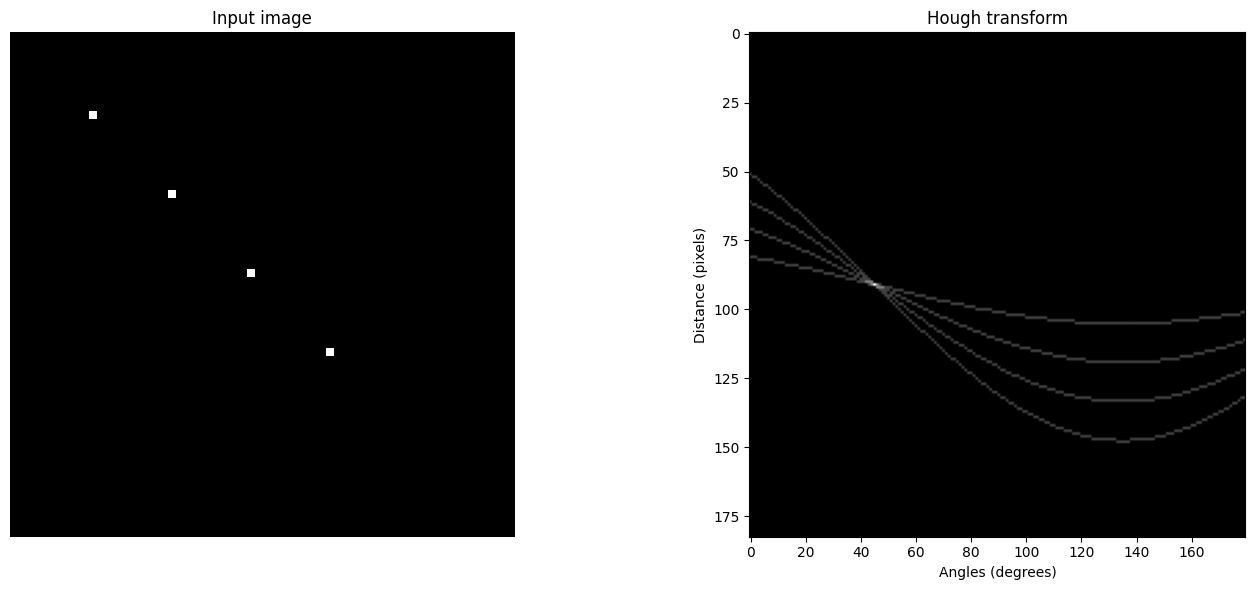

In [34]:
im = np.zeros((64,64), dtype=np.uint8)
im[10, 10] = 1
im[20, 20] = 1
im[30, 30] = 1
im[40, 40] = 1
h, theta, rho = hough_line(im)
show_hough(h, im)

### Transformata Hougha dla pojedynczego obiektu

W tym podpunkcie pokazane zostanie praktycznie wykorzystanie transformaty Hougha - do detekcji prostych na sztucznym rysunku.

   1. Wczytaj obraz "kwadraty.png". Wyświetl go.
   2. Wykonaj detekcję krawędzi jedną z metod gradientowych. Ważne aby obraz krawędzi był jak najlepszej jakości - co oznacza cienkie (nawet niekoniecznie ciągłe) krawędzie - dla tego przypadku nie powinno być trudne do uzyskania. Wyświetl obraz po detekcji krawędzi.
   3. Wykonaj transformatę Hougha obrazu krawędziowego. Wykorzystaj funkcję *hough\_line*.
   4. Wyświetl macierz H. Czy widoczna jest taka liczba maksimów jakiej się spodziewamy?

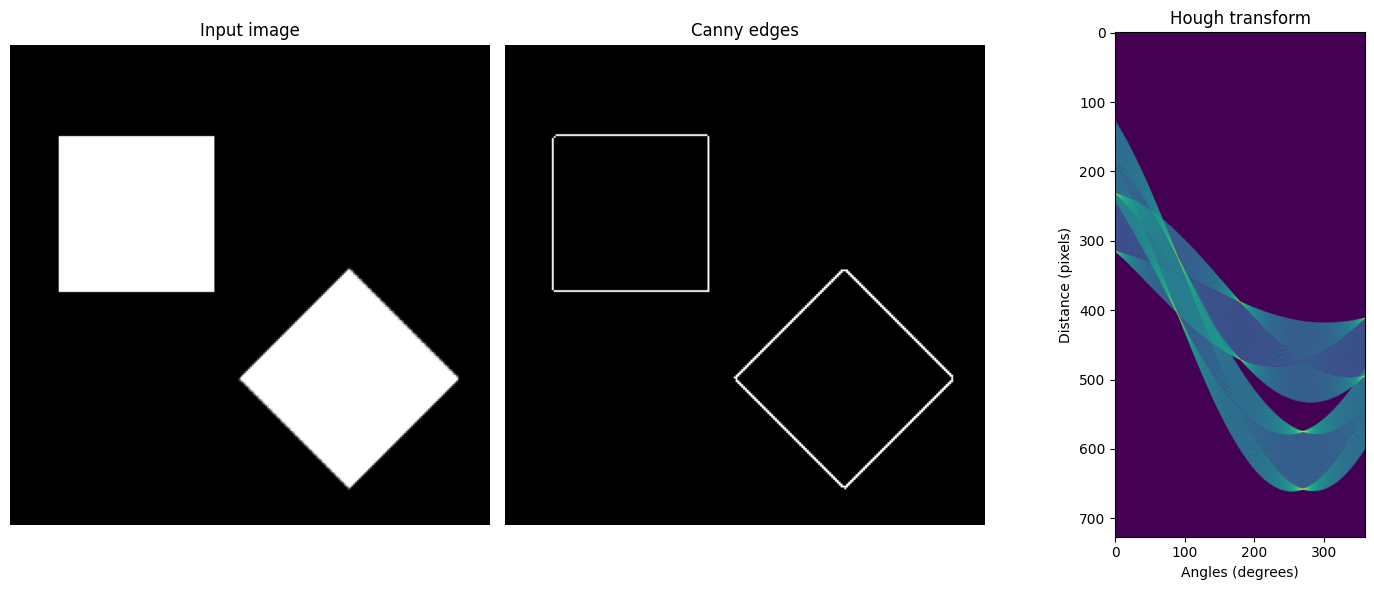

In [35]:
kwadraty = cv2.imread('kwadraty.png', cv2.IMREAD_GRAYSCALE)
kwadraty_edges = cv2.Canny(kwadraty, 50, 150, apertureSize=3)

tested_angles_kw = np.linspace(-np.pi / 2, np.pi / 2, 360, endpoint=False)
h_kw, theta_kw, rho_kw = hough_line(kwadraty_edges, theta=tested_angles_kw)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
ax = axes.ravel()

ax[0].imshow(kwadraty, 'gray')
ax[0].set_title('Input image')
ax[0].set_axis_off()

ax[1].imshow(kwadraty_edges, 'gray')
ax[1].set_title('Canny edges')
ax[1].set_axis_off()

ax[2].imshow(np.log(1 + h_kw)) 
ax[2].set_title('Hough transform')
ax[2].set_xlabel('Angles (degrees)')
ax[2].set_ylabel('Distance (pixels)')

plt.tight_layout()
plt.show()

 5. W module skimage.transform dostępna jest funkcja do automatycznej analizy przestrzeni Hougha - wyszukiwania maksimów - *hough\_line\_peaks*. Jako parametry przyjmuje ona wyniki funkcji *hough\_line* (macierz H, theta i rho). Dodatkowo można podać próg powyżej którego punkt uznawany jest za maksimum (_threshold_ - domyslnie jest to połowa maksimum w przestrzeni H) oraz liczbę poszukiwanych maksimów (*num_peaks*). Funkcja zwraca współrzędne maksimów. Wykorzystaj funkcję *hough\_line\_peaks* do znalezienia maksimów odpowiadających krawędziom kwadratów.
 6. Wyświetl macierz H używając konstrukcji:

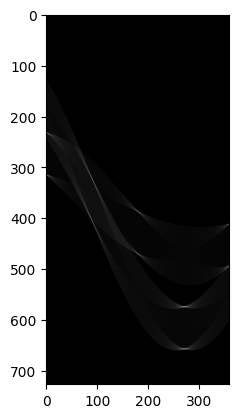

In [36]:
fig,ax = plt.subplots(1)
ax.set_aspect('equal')

ax.imshow(h_kw, 'gray')

Taki zapis pozwoli na dołożenie annotacji (okręgów) w miejscach znalezionych maksimów. Wyrysowanie okręgu w punkcie x, y (o rozmiarze 10, w czerwonym kolorze, bez wypełnienia środka) realizuje wywołanie: 

**circle = plt.Circle((x, y), 10, color='r', fill=False)**

natomiast dołożenie takiego okręgu do obrazu to:

**ax.add_patch(circle)**

Zaznacz maksima na obrazie wykorzystując rezultat funkcji *hough\_line\_peaks* biorąc pod uwagę, że zwraca ona kąty w radianach z przedziału od -pi/2 do pi/2, a rho z przedziału od -r/2 do r/2 gdzie r to pionowy rozmiar przestrzeni Hougha. 

C:\Users\006ma\AppData\Local\Temp\ipykernel_20580\726793312.py:13: RuntimeWarning: divide by zero encountered in divide
  y0, y1 = (dist - origin * np.cos(angle)) / np.sin(angle)


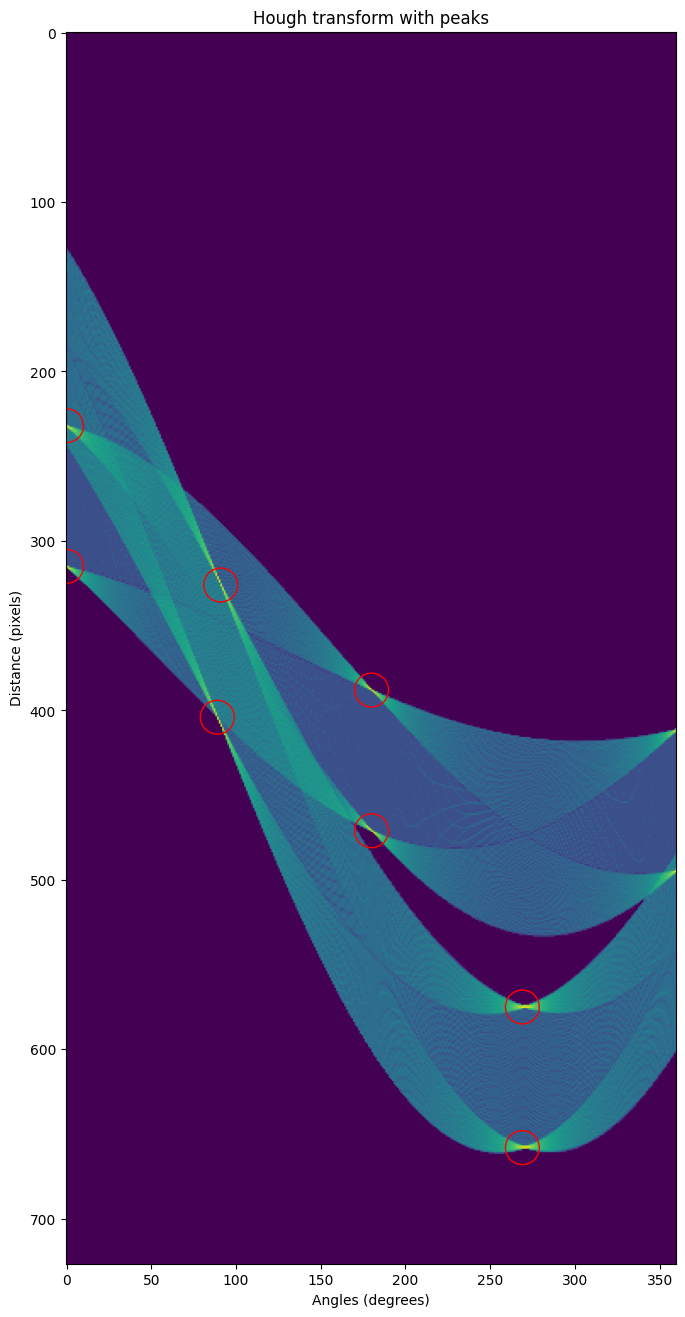

In [37]:
h_kw, theta_kw, rho_kw = hough_line(kwadraty_edges, theta=tested_angles_kw)
hspace, angles, dists = hough_line_peaks(h_kw, theta_kw, rho_kw, num_peaks=8) 

fig,ax = plt.subplots(1, figsize=(8,16))
ax.imshow(np.log(1 + h_kw)) 
ax.set_title('Hough transform with peaks')
ax.set_xlabel('Angles (degrees)')
ax.set_ylabel('Distance (pixels)')

origin = np.array((0, h_kw.shape[1]))

for _, angle, dist in zip(hspace, angles, dists):
    y0, y1 = (dist - origin * np.cos(angle)) / np.sin(angle)
    angle_idx = np.argmin(np.abs(theta_kw - angle))
    dist_idx = np.argmin(np.abs(rho_kw - dist))


    circle = plt.Circle((angle_idx, dist_idx), 10, color='r', fill=False)
    ax.add_patch(circle)

plt.show()

7. Istnieje też możliwość przeprowadzenia transformacji Hougha z użyciem biblioteki OpenCV. W bibliotece znajdują się dwie wersje funkcji wyszukującej linie proste - 'klasyczna' - _HoughLines_ oraz probabilistyczna _HoughLinesP_. Zadna z nich nie zwraca przestrzeni Hougha. Wynikiem działania pierwszej jest lista parametrów prostych (krotki zawierające rho, theta). Druga zwraca krotki 4-ro elementowe ze współrzędnymi końców odcinków wykorzystanych do wylicznia parametrów (czyli znalezienia prostej). 
8. Wyznacz linie obecne na obrazie za pomocą funkcji _HoughLines_. Wykryte linie wyrysuj na obrazie początkowym (UWAGA: wczytanym bez konwersji na graylevel). Do wyświetlania linii wykorzystaj przykładowy kod:

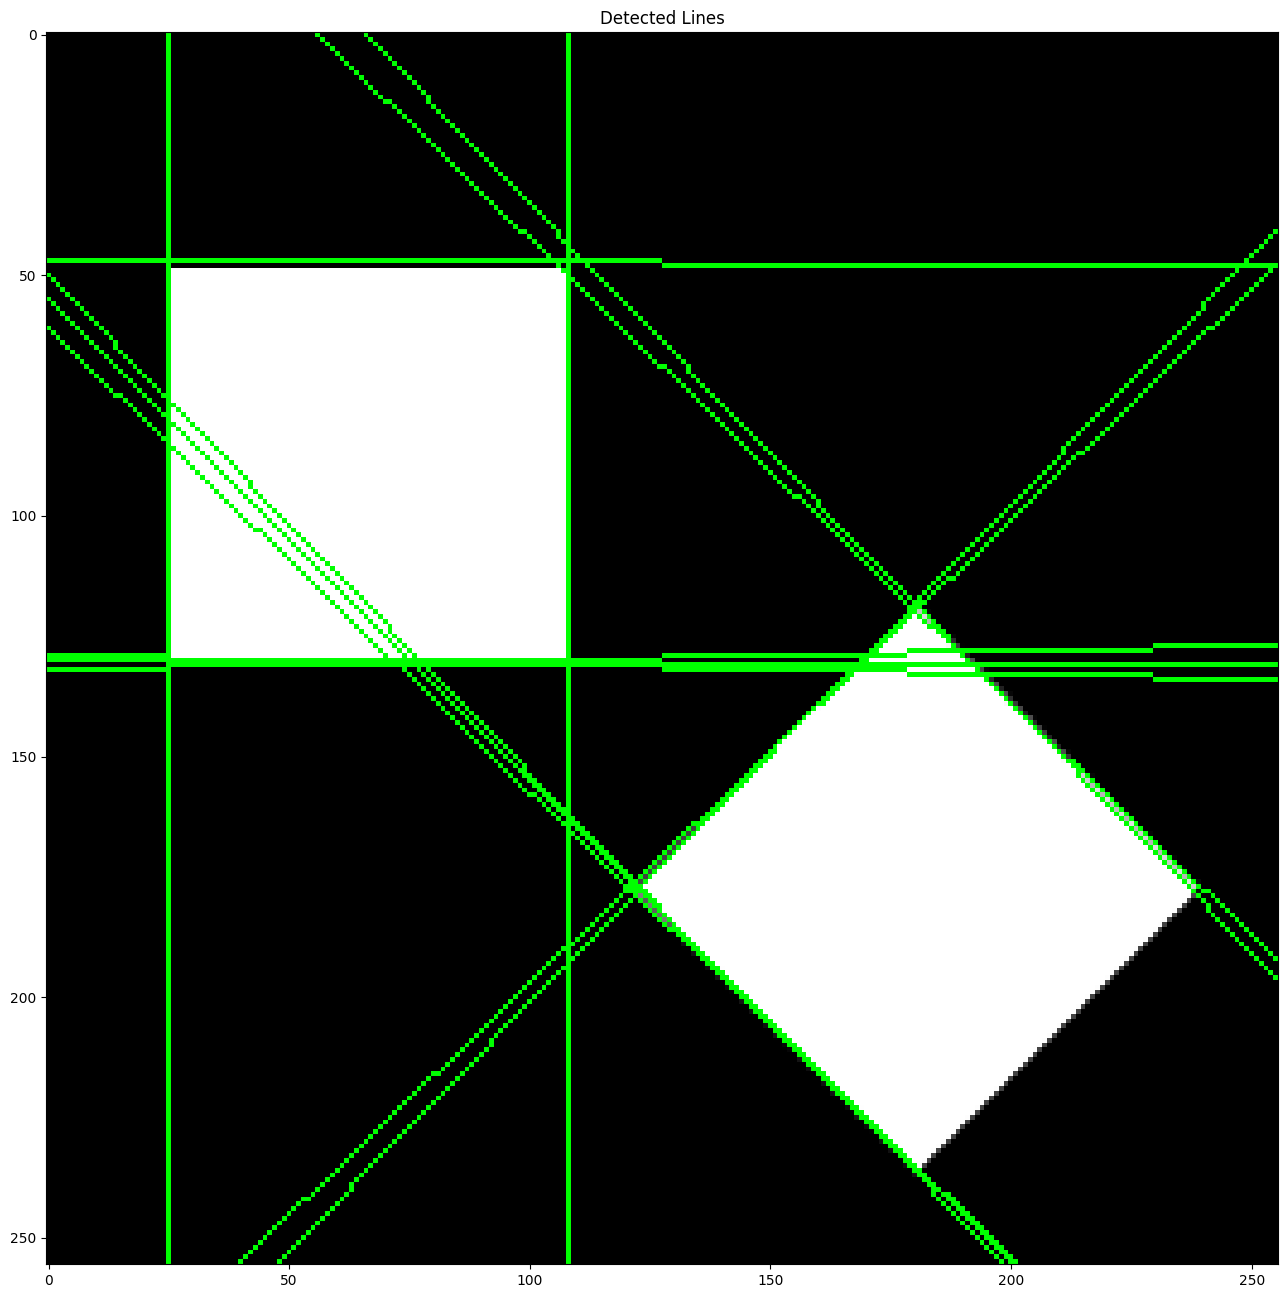

In [38]:
kwadraty_bgr = cv2.imread('kwadraty.png')
kwadraty_gray = cv2.cvtColor(kwadraty_bgr, cv2.COLOR_BGR2GRAY)
kwadraty_edges_cv = cv2.Canny(kwadraty_gray, 50, 150, apertureSize=3)

r = cv2.HoughLines(kwadraty_edges_cv, 1, np.pi / 180, 60)

kwadraty_lines_cv = kwadraty_bgr.copy()

rho, theta = r[:, 0, 0], r[:, 0, 1]

a = np.cos(theta)
b = np.sin(theta)
x0 = rho * np.cos(theta)
y0 = rho * np.sin(theta)
x1 = (x0 + 1000*(-b)).astype(np.int32)
y1 = (y0 + 1000*(a)).astype(np.int32)
x2 = (x0 - 1000*(-b)).astype(np.int32)
y2 = (y0 - 1000*(a)).astype(np.int32)

fig,ax = plt.subplots(1, figsize=(16, 16))
sq = cv2.cvtColor(kwadraty, cv2.COLOR_GRAY2RGB)
for i in range(r.shape[0]):
    sq = cv2.line(sq, (x1[i], y1[i]), (x2[i], y2[i]), (0,255,0))

ax.set_title('Detected Lines')
ax.imshow(sq)
plt.show()


9. Wyznacz odcinki obecne na obrazie za pomocą funkcji _HoughLinesP_. Wykryte odcinki wyrysuj na obrazie początkowym (UWAGA: wczytanym bez konwersji na graylevel). 

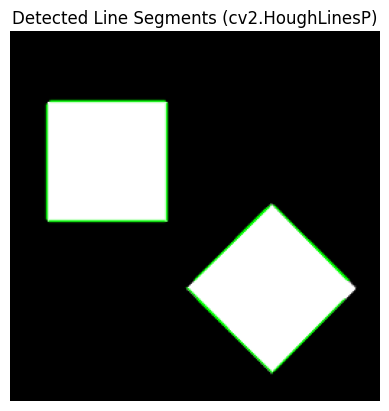

In [39]:
kwadraty_bgr_p = cv2.imread('kwadraty.png')
kwadraty_gray_p = cv2.cvtColor(kwadraty_bgr_p, cv2.COLOR_BGR2GRAY)
kwadraty_edges_p = cv2.Canny(kwadraty_gray_p, 50, 150, apertureSize = 3)

linesP = cv2.HoughLinesP(kwadraty_edges_p, 1, np.pi / 180, 40)

kwadraty_lines_p = kwadraty_bgr_p.copy()

if linesP is not None:
    for i in range(0, len(linesP)):
        l = linesP[i][0]
        cv2.line(kwadraty_lines_p, (l[0], l[1]), (l[2], l[3]), (0,255,0), 1, cv2.LINE_AA)

plt.imshow(cv2.cvtColor(kwadraty_lines_p, cv2.COLOR_BGR2RGB))
plt.title('Detected Line Segments (cv2.HoughLinesP)')
plt.axis('off')
plt.show()

### Transformata Hougha dla obrazu rzeczywistego.

Bazując na kodzie stworzonym w punkcie B wyszukamy linie na obrazie rzeczywistym.
   1. Wczytaj obraz "lab112.png". Wyświetl go.
   2. Wykorzystując wszystkie poznane techniki przetwarzania obrazów (filtracja, przekształcenia morfologiczne, binaryzację, detekcję krawędzi) wyodrębnij krawędzie samych kwadratów - tak aby były jak najlepszej jakości (cienkie) - jednocześnie eliminując z obrazu zakłócenia.
   3. Wykorzystaj funkcje *hough_line* i *hough_line_peaks* do detekcji linii na obrazie, a następnie np. wykorzystując kod z punktu 8 poprzedniego ustępu wyrysuj na oryginalnym obrazie znalezione linie.

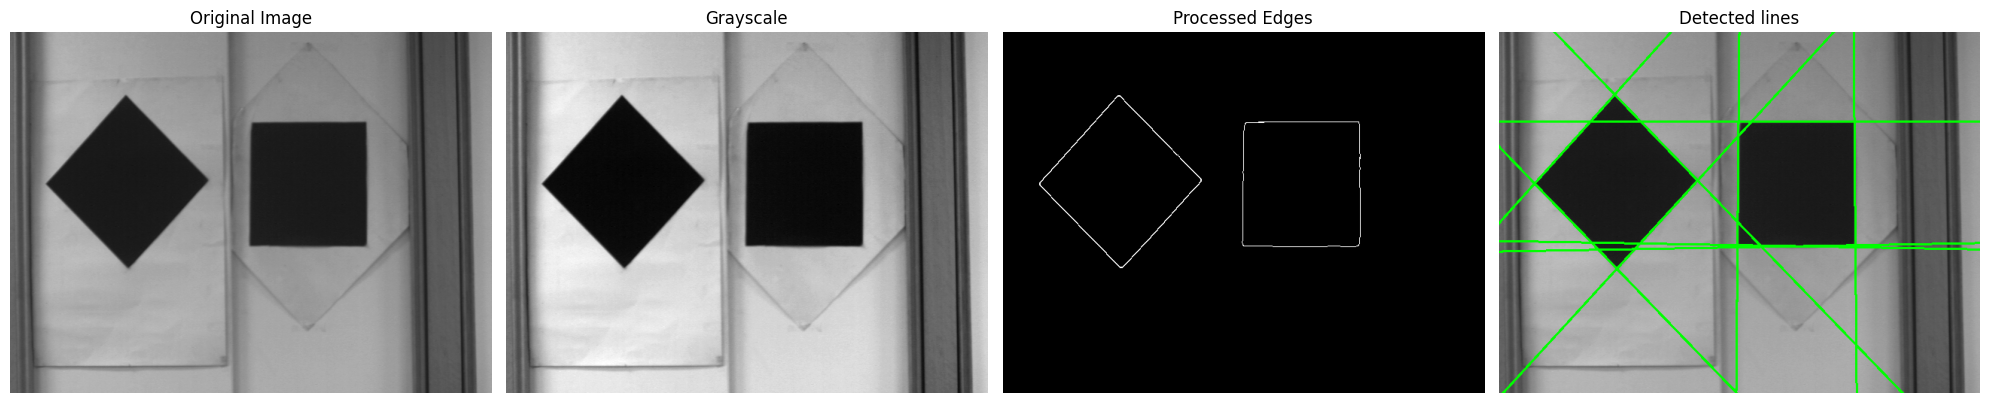

In [40]:
lab112_bgr = cv2.imread('lab112.png')
lab112_gray = cv2.imread('lab112.png', cv2.IMREAD_GRAYSCALE)

lab112_blur = cv2.GaussianBlur(lab112_gray, (5, 5), 0)
lab112_edges = cv2.Canny(lab112_blur, 100, 200, apertureSize=3)

kernel = np.ones((3,3), np.uint8)
lab112_edges_dilated = cv2.dilate(lab112_edges, kernel, iterations=1)
lab112_edges_final = cv2.erode(lab112_edges_dilated, kernel, iterations=1)


tested_angles_lab = np.linspace(-np.pi / 2, np.pi / 2, 360, endpoint=False)
h_lab, theta_lab, rho_lab = hough_line(lab112_edges_final, theta=tested_angles_lab)


hspace_lab, angles_lab, dists_lab = hough_line_peaks(h_lab, theta_lab, rho_lab, threshold=0.3 * np.max(h_lab), num_peaks=10)

lab112_lines_skimage = lab112_bgr.copy()


fig, axes = plt.subplots(1, 4, figsize=(20, 6))
ax = axes.ravel()

ax[0].imshow(cv2.cvtColor(lab112_bgr, cv2.COLOR_BGR2RGB))
ax[0].set_title('Original Image')
ax[0].set_axis_off()

ax[1].imshow(lab112_gray, 'gray')
ax[1].set_title('Grayscale')
ax[1].set_axis_off()

ax[2].imshow(lab112_edges_final, 'gray')
ax[2].set_title('Processed Edges')
ax[2].set_axis_off()


ax[3].imshow(cv2.cvtColor(lab112_lines_skimage, cv2.COLOR_BGR2RGB))
ax[3].set_ylim((lab112_lines_skimage.shape[0], 0))
ax[3].set_xlim((0, lab112_lines_skimage.shape[1]))
ax[3].set_axis_off()
ax[3].set_title('Detected lines')

for _, angle, dist in zip(hspace_lab, angles_lab, dists_lab):
    rho = dist
    theta = angle
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*rho
    y0 = b*rho
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))
    cv2.line(lab112_lines_skimage,(x1,y1),(x2,y2),(0,255,0),2)

ax[3].imshow(cv2.cvtColor(lab112_lines_skimage, cv2.COLOR_BGR2RGB))

plt.tight_layout()
plt.show()

4. Wczytaj obraz "dom.png". Wypróbuj działanie transformacji Hougha na tym obrazie z wykorzystaniem funkcji _cv2.HoughLinesP_  (oczywiście po odpowiednich przekształceniach). Postaraj się tak przygotować obraz z krawędziami i dobrać parametry aby wyrysować na oryginalnym obrazie odcinki obejmujące zarysy domu. Weź pod uwage dodatkowe parametry funkcji, takie jak:   minLineLength, maxLineGap.

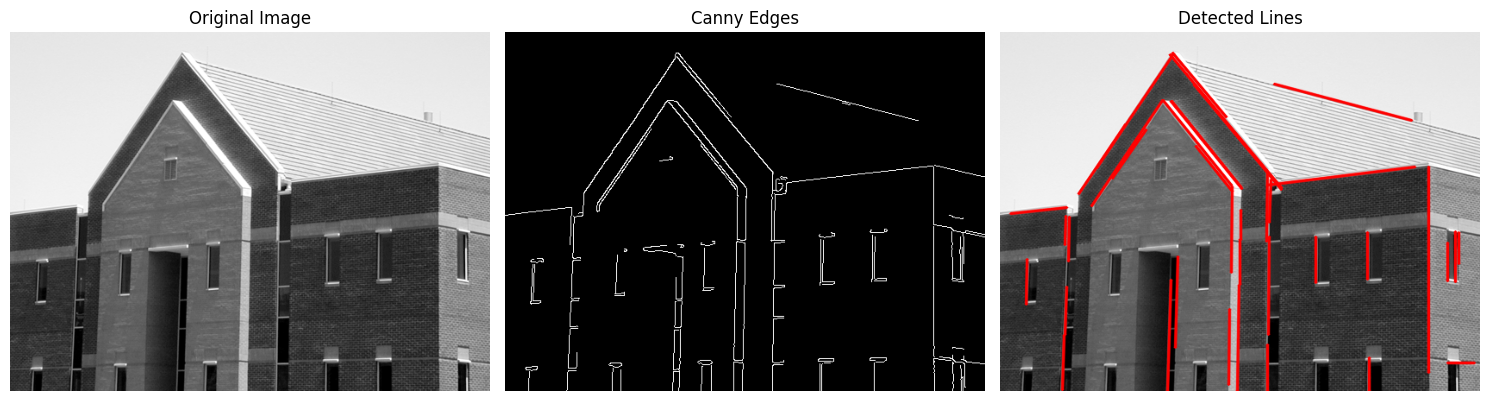

In [41]:
dom_bgr = cv2.imread('dom.png')
dom_gray = cv2.imread('dom.png', cv2.IMREAD_GRAYSCALE)

dom_blur = cv2.GaussianBlur(dom_gray, (3, 3), 0)
dom_edges = cv2.Canny(dom_blur, 150, 255, None, 3, 2)

dom_lines_p = dom_bgr.copy()

linesP_dom = cv2.HoughLinesP(dom_edges, 1, np.pi / 180, threshold=50, minLineLength=30, maxLineGap=10)

if linesP_dom is not None:
    for i in range(0, len(linesP_dom)):
        l = linesP_dom[i][0]
        cv2.line(dom_lines_p, (l[0], l[1]), (l[2], l[3]), (0,0,255), 2, cv2.LINE_AA)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
ax = axes.ravel()

ax[0].imshow(cv2.cvtColor(dom_bgr, cv2.COLOR_BGR2RGB))
ax[0].set_title('Original Image')
ax[0].set_axis_off()

ax[1].imshow(dom_edges, 'gray')
ax[1].set_title('Canny Edges')
ax[1].set_axis_off()

ax[2].imshow(cv2.cvtColor(dom_lines_p, cv2.COLOR_BGR2RGB))
ax[2].set_title('Detected Lines')
ax[2].set_axis_off()

plt.tight_layout()
plt.show()